some experiments with the geo and spatial data analysis 

In [41]:
# imports 

import geopandas as gpd
from shapely.geometry import Point
import osmnx as ox



In [42]:
locations = {"name": ["Senate House","Russell Square"]}

geometry = [Point(-0.1300, 51.5215),Point(-0.1250, 51.5225)]

gdf = gpd.GeoDataFrame(locations,geometry=geometry,crs="EPSG:4326")

print(gdf)
print(gdf.crs)

             name                geometry
0    Senate House   POINT (-0.13 51.5215)
1  Russell Square  POINT (-0.125 51.5225)
EPSG:4326


In [43]:
projected = gdf.to_crs("EPSG:32630")

distance = projected.geometry.iloc[0].distance(projected.geometry.iloc[1])

print(distance, "meters")

364.46566774053025 meters


In [44]:
# create two points 
geometry = [Point(-0.1300, 51.5215) ,Point(-0.1250, 51.5225)]
locations = {'name' :['l_1' , 'l_2']}
gdf = gpd.GeoDataFrame( locations , geometry= geometry ,crs = 'EPSG:4326')
print(gdf.crs)

EPSG:4326


In [45]:
# project the gdf to planar 
projected = gdf.to_crs('EPSG:32630')
projected

,name,geometry
0,l_1,POINT (699102.075 5711725.435)
1,l_2,POINT (699444.506 5711850.24)


In [46]:
gdf.geometry[0].distance(gdf.geometry[1])

0.0050990195135923325

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

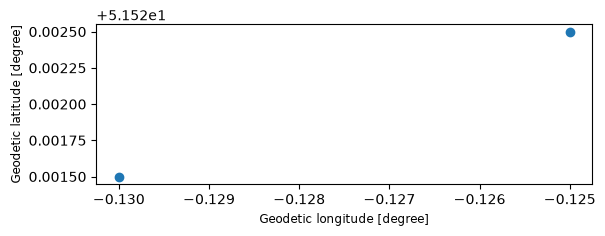

In [47]:
gdf.plot()

In [48]:
from shapely.geometry import LineString

#create a new line string with multiple sequences 
l = LineString([(0,0) , (3,4) ,(5,2)])

print(f'''
    length :{l.length}
    type : {l.geom_type} 
    coords : {l.coords}
    bounds : {l.bounds}
    validation : {l.is_valid}
        ''')




    length :7.82842712474619
    type : LineString 
    coords : <shapely.coords.CoordinateSequence object at 0x7a92f9854d60>
    bounds : (0.0, 0.0, 5.0, 4.0)
    validation : True
        


In [49]:


print(l.interpolate(3)) # 3 units away from the beginning 
# this is the same as 
print(((0 + ((3/5) * 3 )) , (0 + ((3/5) * 4 )))) #starting from the beginning we can try to trace the road segment 



POINT (1.7999999999999998 2.4)
(1.7999999999999998, 2.4)


In [50]:


point = l.interpolate(0.5 , normalized= True)
print(point)


POINT (2.348528137423857 3.131370849898476)


In [51]:
from shapely.geometry import Point
location = Point(1.8,2.4)
distance_along_road = l.project(location)
print(distance_along_road)


3.0


In [52]:
from shapely.geometry import Point
from shapely.ops import nearest_points

road = LineString([Point(0,0) , Point(0,10)])
location = Point(4,3)
nearest_on_road, nearest_on_gps = nearest_points(road , location)
print(nearest_on_road)
# we can even find the least distance 
road.distance(location)


POINT (0 3)


4.0

In [53]:
road_buffer = road.buffer(30)
print(road_buffer)

POLYGON ((-30 10, -29.855541800165906 12.940514209886825, -29.423558412096913 15.852709660483859, -28.708210071966263 18.708540317633872, -27.716385975338603 21.4805029709527, -26.457637930450648 24.141902104779938, -24.94408836907636 26.667106990588067, -23.19031360088211 29.031798524909366, -21.213203435596423 31.213203435596427, -19.031798524909362 33.190313600882114, -16.66710699058806 34.94408836907637, -14.14190210477993 36.45763793045065, -11.480502970952692 37.7163859753386, -8.708540317633865 38.70821007196626, -5.852709660483846 39.42355841209691, -2.9405142098868193 39.85554180016591, 0 40, 2.940514209886823 39.85554180016591, 5.85270966048385 39.42355841209691, 8.70854031763387 38.70821007196626, 11.480502970952696 37.7163859753386, 14.141902104779934 36.457637930450645, 16.667106990588064 34.94408836907636, 19.031798524909366 33.19031360088211, 21.213203435596427 31.213203435596423, 23.19031360088211 29.031798524909362, 24.94408836907636 26.667106990588064, 26.457637930450

In [54]:
print(road_buffer.geom_type)

Polygon


In [55]:
road_b = LineString([(3,2), (12,5),(6,7)])
road_a = LineString([(5,3), (12,2),(4,9)])


In [56]:
print(road_a.intersects(road_b))

True


In [57]:
road_a.crosses(road_b)

True

In [58]:
road_a.overlaps(road_b)

False

In [59]:
# park.contains(location)
# location.within(park)

In [60]:
from shapely.geometry import LineString, Point

road_a = LineString([
    (0, 0),
    (10, 0)
])

road_b = LineString([
    (5, -5),
    (5, 5)
])

intersection = road_a.intersection(road_b)

print(intersection)
print(intersection.geom_type)

POINT (5 0)
Point


In [61]:
import geopandas as gpd

from shapely.geometry import Point, Polygon

parks = gpd.GeoDataFrame(
    {
        "park": ["Park A", "Park B"]
    },
    geometry=[
        Polygon([
            (0, 0),
            (10, 0),
            (10, 10),
            (0, 10)
        ]),
        Polygon([
            (20, 0),
            (30, 0),
            (30, 10),
            (20, 10)
        ])
    ],
    crs="EPSG:32630"
)


buildings = gpd.GeoDataFrame(
    {
        "building": [
            "Building 1",
            "Building 2",
            "Building 3"
        ]
    },
    geometry=[
        Point(5, 5),
        Point(25, 5),
        Point(15, 5)
    ],
    crs="EPSG:32630"
)


In [62]:
result = gpd.sjoin(parks , buildings , how= 'inner' , predicate= 'contains')
result

,park,geometry,index_right,building
0,Park A,"POLYGON ((0 0, 10 0, 10 10, 0 10, 0 0))",0,Building 1
1,Park B,"POLYGON ((20 0, 30 0, 30 10, 20 10, 20 0))",1,Building 2


In [63]:
result = gpd.sjoin(
    buildings,
    parks,
    how="left",
    predicate="within"
)

print(result)

     building      geometry  index_right    park
0  Building 1   POINT (5 5)          0.0  Park A
1  Building 2  POINT (25 5)          1.0  Park B
2  Building 3  POINT (15 5)          NaN     NaN


In [64]:
#imports 
import osmnx as ox
from pathlib import Path


#some assets 
CENTER_POINT = (51.5215, -0.1300)
path = Path('/home/lenovo/projects/London_Traffic/data/network.graphml')

In [65]:
G = ox.load_graphml(path)

In [66]:
G_Projected = ox.projection.project_graph(G)
nodes , edges  = ox.graph_to_gdfs(G_Projected, nodes = True , edges  = True)
nodes.head(5)

,y,x,street_count,highway,junction,geometry
osmid,,,,,,
101986,5.711774e+06,698100.152684,4,NaN,NaN,POINT (698100.153 5711774.148)
5560625852,5.711779e+06,698116.135439,2,NaN,NaN,POINT (698116.135 5711778.981)
12337135370,5.711780e+06,698098.301729,2,crossing,NaN,POINT (698098.302 5711780.1)
13703116050,5.711770e+06,698101.381874,2,give_way,NaN,POINT (698101.382 5711770.421)
102000,5.711536e+06,698225.562346,4,NaN,NaN,POINT (698225.562 5711536.165)


In [67]:
nodes.head(5)

,y,x,street_count,highway,junction,geometry
osmid,,,,,,
101986,5.711774e+06,698100.152684,4,NaN,NaN,POINT (698100.153 5711774.148)
5560625852,5.711779e+06,698116.135439,2,NaN,NaN,POINT (698116.135 5711778.981)
12337135370,5.711780e+06,698098.301729,2,crossing,NaN,POINT (698098.302 5711780.1)
13703116050,5.711770e+06,698101.381874,2,give_way,NaN,POINT (698101.382 5711770.421)
102000,5.711536e+06,698225.562346,4,NaN,NaN,POINT (698225.562 5711536.165)


In [68]:
edges.head(5)

osmid       highway lanes maxspeed  \
u           v           key                                            
101986      5560625852  0     114925568  unclassified     2   20 mph   
            12337135370 0    1086461668   residential   NaN   20 mph   
            13703116050 0    1086461669   residential   NaN   20 mph   
5560625852  7198104013  0     581022359  unclassified     2   20 mph   
12337135370 101986      0    1086461668   residential   NaN   20 mph   

                                          name  oneway  reversed     length  \
u           v           key                                                   
101986      5560625852  0    Devonshire Street    True     False  16.646055   
            12337135370 0        Hallam Street   False      True   6.227905   
            13703116050 0        Hallam Street   False     False   3.920988   
5560625852  7198104013  0    Devonshire Street    True     False  20.108220   
12337135370 101986      0        Hallam Street   False     False   6.227905   

                             ref access width bridge tunnel junction  \
u           v           key                                            
101986      5560625852  0    NaN    NaN   NaN    NaN    NaN      NaN   
            12337135370 0    NaN    NaN   NaN    NaN    NaN      NaN   
            13703116050 0    NaN    NaN   NaN    NaN    NaN      NaN   
5560625852  7198104013  0    NaN    NaN   NaN    NaN    NaN      NaN   
12337135370 101986      0    NaN    NaN   NaN    NaN    NaN      NaN   

                                                                      geometry  
u           v           key                                                     
101986      5560625852  0    LINESTRING (698100.153 5711774.148, 698116.135...  
            12337135370 0    LINESTRING (698100.153 5711774.148, 698098.302...  
            13703116050 0    LINESTRING (698100.153 5711774.148, 698101.382...  
5560625852  7198104013  0    LINESTRING (698116.135 5711778.981, 698135.338...  
12337135370 101986      0    LINESTRING (698098.302 5711780.1, 698100.153 5...

In [69]:
node_id = list(G_Projected.nodes)[0]
G.nodes[node_id]

{'y': 51.5222897, 'x': -0.1443957, 'street_count': 4}

In [70]:
#lets inspect the outgoing edges of the node 

for edge in G.out_edges(node_id , keys= True, data = True):
    print(edge)
    


(101986, 5560625852, 0, {'osmid': 114925568, 'highway': 'unclassified', 'lanes': '2', 'maxspeed': '20 mph', 'name': 'Devonshire Street', 'oneway': True, 'reversed': False, 'length': 16.646054594356144})
(101986, 12337135370, 0, {'osmid': 1086461668, 'highway': 'residential', 'maxspeed': '20 mph', 'name': 'Hallam Street', 'oneway': False, 'reversed': True, 'length': 6.227904659698362})
(101986, 13703116050, 0, {'osmid': 1086461669, 'highway': 'residential', 'maxspeed': '20 mph', 'name': 'Hallam Street', 'oneway': False, 'reversed': False, 'length': 3.920988071242493})


In [71]:
for edge in G.in_edges(node_id ,keys = True , data = True ):
    print(edge)
    

(12337135370, 101986, 0, {'osmid': 1086461668, 'highway': 'residential', 'maxspeed': '20 mph', 'name': 'Hallam Street', 'oneway': False, 'reversed': False, 'length': 6.227904659698362})
(13703116050, 101986, 0, {'osmid': 1086461669, 'highway': 'residential', 'maxspeed': '20 mph', 'name': 'Hallam Street', 'oneway': False, 'reversed': True, 'length': 3.920988071242493})


In [72]:
next_node_id = list(G.successors(node_id ))[0]
print(next_node_id) # this gives us  the next node s id not the node itself 
G.nodes[next_node_id]

5560625852


{'y': 51.5223275, 'x': -0.1441629, 'street_count': 2}

In [73]:
previous_node = list(G.predecessors(node_id))[0]
G.nodes[previous_node]

{'y': 51.5223438, 'x': -0.144419, 'highway': 'crossing', 'street_count': 2}

In [74]:

node = list(G.nodes)[0]
print('in degree : ', G.in_degree(node))
print('out degree : ', G.out_degree(node))
print('total degree : ', G.degree(node))


in degree :  2
out degree :  3
total degree :  5


In [75]:
street_counts = [data.get('street_count' , 0) for node , data in G.nodes(data = True)]
print('maximum :' , max(street_counts))
print('minimum :' , min(street_counts))
print("Number of nodes:", len(street_counts))

maximum : 5
minimum : 1
Number of nodes: 5667


In [76]:
street_counts = ox.stats.count_streets_per_node(G)
street_counts

{101986: 3,
 102000: 4,
 102005: 4,
 104302: 4,
 104305: 2,
 105511: 4,
 106201: 4,
 106203: 3,
 106211: 4,
 106213: 4,
 107316: 3,
 107317: 3,
 107318: 4,
 107319: 4,
 107320: 3,
 107322: 4,
 107324: 3,
 107325: 2,
 107326: 3,
 107327: 2,
 107328: 3,
 107333: 3,
 107341: 3,
 107343: 4,
 107345: 3,
 107348: 3,
 107349: 4,
 107351: 3,
 107352: 4,
 107792: 4,
 107805: 3,
 107823: 2,
 107828: 4,
 107829: 3,
 107830: 4,
 107831: 4,
 107833: 2,
 107835: 3,
 107836: 3,
 107837: 3,
 107838: 3,
 107839: 3,
 107843: 3,
 107844: 3,
 107848: 3,
 107851: 3,
 107852: 3,
 107853: 4,
 107855: 3,
 107856: 4,
 107857: 2,
 107860: 3,
 107863: 3,
 107864: 3,
 107865: 3,
 107866: 3,
 107867: 3,
 107869: 3,
 107870: 2,
 107871: 2,
 107872: 2,
 107873: 3,
 107875: 2,
 107876: 3,
 107877: 3,
 107878: 4,
 107879: 4,
 107881: 3,
 107882: 3,
 107884: 3,
 107885: 2,
 107887: 3,
 107888: 2,
 107889: 3,
 107890: 3,
 107891: 3,
 107895: 3,
 107896: 3,
 107978: 2,
 107981: 4,
 107982: 2,
 107984: 2,
 107986: 3,
 107

In [77]:

import networkx as nx 

components = list(nx.weakly_connected_components(G))
print('number of weak components :' , len(components))
print('largest component :' , max(map(len, components)))



number of weak components : 1
largest component : 5667


In [78]:
strong_components = list(nx.strongly_connected_components(G))
print('number of strongly components :' , len(strong_components))

number of strongly components : 344


In [79]:
if nx.has_path(G, origin, destination):
    print("A directed route exists!")
else:
    print("No directed route exists.")

NameError: name 'origin' is not defined

In [80]:
nearest_node = ox.distance.nearest_nodes(G_Projected, X = -0.1300 , Y = 51.5215) 
#this is incorrect as the graph  and the longtitude and latitude are not the same crs 
print('nearest node :' , G_Projected.nodes[nearest_node])

nearest node : {'y': 5710695.634905789, 'x': 698230.7202277001, 'street_count': 2, 'highway': 'traffic_signals'}


In [81]:
import geopandas as gpd 
from shapely.geometry import Point

point = gpd.GeoSeries([Point(-0.1300 , 51.5215)] , crs= 'EPSG:4326')
# we should project this point to our graph s crs 
projected_point = point.to_crs(G_Projected.graph['crs'] )

x = projected_point.iloc[0].x
y = projected_point.iloc[0].y

print(x , y)

699102.0750637369 5711725.435422775


In [82]:

#now we can find the nearest node correctly 
nearest_edge = ox.distance.nearest_edges(G_Projected , X = x , Y  = y)
nearest_edge



(8166172620, 9300541906, 0)

In [83]:
u, v, key = nearest_edge

edge = G_Projected.edges[u, v, key]

print("Length:", edge["length"])
print("Road type:", edge.get("highway"))
print("Road name:", edge.get("name"))

Length: 29.384487665082297
Road type: residential
Road name: Malet Street


In [84]:
route = nx.shortest_path(
    G_Projected,
    source=origin,
    target=destination,
    weight="length",
    method="dijkstra"
)

print(route) # ---> bunch of node ids that we have to find the edges for 

NameError: name 'origin' is not defined

In [ ]:
def get_route_edges(G, route):
    route_edges = []

    for u, v in zip(route[:-1], route[1:]):
        parallel_edges = G.get_edge_data(u, v)

        best_key = min(
            parallel_edges,
            key=lambda k: parallel_edges[k]["length"]
        )

        route_edges.append((u, v, best_key))

    return route_edges

map matching and analysis 

In [ ]:
# first you must project every road to an appropriate crs with units in meters 
import geopandas as gpd
from shapely.geometry import LineString

road = LineString([
    (-0.1305, 51.5210),
    (-0.1302, 51.5213),
    (-0.1298, 51.5216)
])

road_gdf = gpd.GeoDataFrame(
    {"name": ["Example road"]},
    geometry=[road],
    crs="EPSG:4326"
)

road_metric = road_gdf.to_crs("EPSG:32630")

print(road_metric.geometry.iloc[0].length)



In [85]:
G_projected = ox.projection.project_graph(G)

nodes_projected, edges_projected = (
    ox.convert.graph_to_gdfs(G_projected)
)

In [88]:
print(edges_projected.index.names)

['u', 'v', 'key']


In [ ]:
from shapely.geometry import Point, LineString

road = LineString([
    (100, 100),
    (200, 100),
    (300, 100)
])

gps_point = Point(180, 115)

distance = gps_point.distance(road) #this is the distance from point perpendicualr to the road 

print(distance)

15.0


In [92]:

closest_point = road.interpolate(
    road.project(gps_point)
)
print(closest_point)


POINT (180 100)


In [95]:
tomtom_line = LineString([
    (699000, 5712000),
    (699100, 5712050),
    (699200, 5712100)
])

search_area = tomtom_line.buffer(25)

candidate_positions = (edges_projected.sindex.query(search_area , predicate= 'intersects'))

candidates = edges_projected.iloc[candidate_positions]
print(candidates)

                                 osmid      highway lanes maxspeed  \
u           v           key                                          
2453162763  485257315   0    237413929  residential     2   20 mph   
485257315   2453162763  0    237413929  residential     2   20 mph   
7993080666  5379465518  0     17513383  residential   NaN   20 mph   
5379465518  7993080666  0     17513383  residential   NaN   20 mph   
            485257385   0     17513383  residential   NaN   20 mph   
485257385   5379465518  0     17513383  residential   NaN   20 mph   
            12409499700 0     17513383  residential   NaN   20 mph   
12409499700 485257385   0     17513383  residential   NaN   20 mph   
3113622364  3113622361  0    306452424      primary     3   20 mph   
3113622361  3113622364  0    306452424      primary     3   20 mph   
3113622364  3113617870  0    306452424      primary     3   20 mph   
3113617870  3113622364  0    306452424      primary     3   20 mph   

                   

In [ ]:

print(list(road.coords))


[(100.0, 100.0), (200.0, 100.0), (300.0, 100.0)]


In [99]:
#only finding the candidates for the tomtom segment is not enough we should also compare its direction 
import math 
def calculate_heading(line):
    start = line.coords[0]
    end = line.coords[-1]
    
    dx = end[0] - start[0]
    dy = end[1] - start[1]
    
    angle = math.degrees(math.atan2(dx, dy))
    return (angle + 360) % 360



In [100]:
eastbound = LineString([
    (0, 0),
    (100, 0)
])

westbound = LineString([
    (100, 0),
    (0, 0)
])

print(calculate_heading(eastbound))
print(calculate_heading(westbound))

90.0
270.0
